# Tarea Práctica – Clase 5: Comparación de Clasificadores (Dataset de Vinos)

**Objetivos**
1. Identificar la **3.ª columna más representativa** mediante un mapa de calor de correlaciones.
2. Graficar la 3.ª columna contra la 1.ª (**Alcohol**) y contra la 2.ª (**Flavonoides**).
3. Aplicar **k-NN, Árbol de Decisión y Naive Bayes** sobre esas dos parejas y decidir cuál ofrece la representación gráfica más clara.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

mapeo_columnas = {
    'alcohol': 'Alcohol', 'malic_acid': 'Acido_Malico', 'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza', 'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales', 'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas', 'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz', 'od280/od315_of_diluted_wines': 'OD280_OD315', 'proline': 'Prolina'
}
X.rename(columns=mapeo_columnas, inplace=True)
print("Datos cargados:", X.shape)

Datos cargados: (178, 13)


---
## Paso 1: Mapa de calor y 3.ª columna más representativa

Calculamos la matriz de correlaciones de todas las características **incluyendo la clase de vino**. La fila/columna `Clase_de_Vino` indica qué tan relacionada está cada variable con lo que queremos predecir.

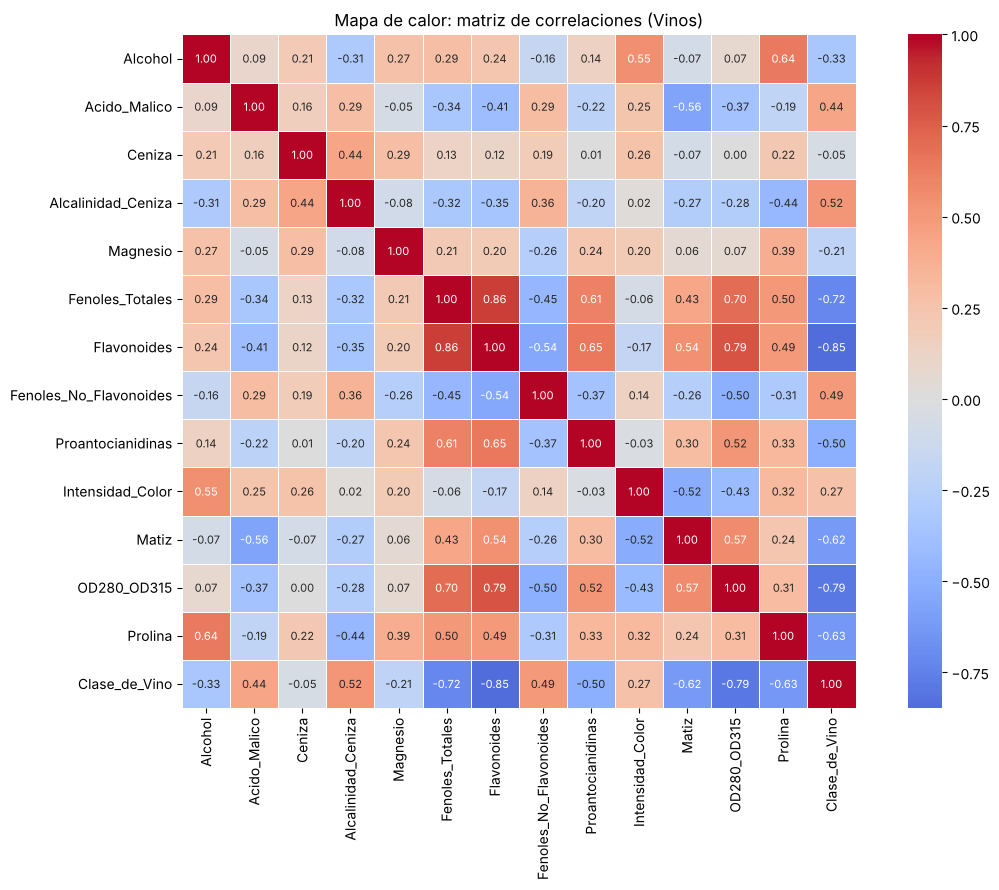

In [2]:
datos = pd.concat([X, y], axis=1)
corr = datos.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, annot_kws={'size': 8})
plt.title('Mapa de calor: matriz de correlaciones (Vinos)')
plt.tight_layout()
plt.show()

,|Correlación con la clase|
Flavonoides,0.847
OD280_OD315,0.788
Fenoles_Totales,0.719
Prolina,0.634
Matiz,0.617
Alcalinidad_Ceniza,0.518
Proantocianidinas,0.499
Fenoles_No_Flavonoides,0.489
Acido_Malico,0.438
Alcohol,0.328


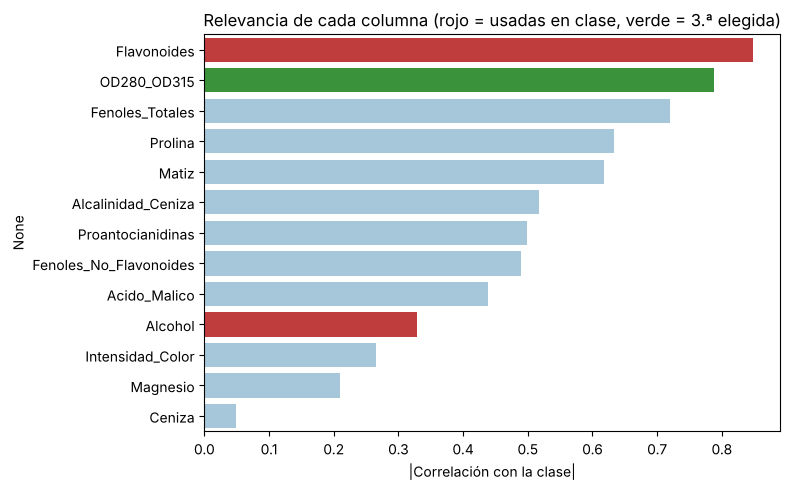

In [3]:
# Relevancia = |correlación| de cada característica con la clase
relevancia = corr['Clase_de_Vino'].drop('Clase_de_Vino').abs().sort_values(ascending=False)
display(relevancia.to_frame('|Correlación con la clase|').round(3))

plt.figure(figsize=(8, 5))
colores = ['#d62728' if c in ('Alcohol', 'Flavonoides') else ('#2ca02c' if c == 'OD280_OD315' else '#9ecae1')
           for c in relevancia.index]
sns.barplot(x=relevancia.values, y=relevancia.index, palette=colores)
plt.xlabel('|Correlación con la clase|')
plt.title('Relevancia de cada columna (rojo = usadas en clase, verde = 3.ª elegida)')
plt.tight_layout()
plt.show()

In [4]:
# 3.ª columna: la más correlacionada con la clase, aparte de las dos usadas en clase
TERCERA = relevancia.drop(['Alcohol', 'Flavonoides']).index[0]
print("3.ª columna seleccionada:", TERCERA, f"(|r| = {relevancia[TERCERA]:.3f})")
print("Correlación con Alcohol:      ", round(corr.loc[TERCERA, 'Alcohol'], 3))
print("Correlación con Flavonoides:  ", round(corr.loc[TERCERA, 'Flavonoides'], 3))

3.ª columna seleccionada: OD280_OD315 (|r| = 0.788)
Correlación con Alcohol:       0.072
Correlación con Flavonoides:   0.787


**Interpretación.** Los **Flavonoides** son la variable más relacionada con la clase (|r| ≈ 0.85) y **OD280_OD315** es la siguiente (|r| ≈ 0.79), por lo que se elige como **3.ª columna** al excluir las dos usadas en clase. Además tiene una correlación alta con Flavonoides (≈ 0.79), pero baja con el Alcohol (≈ 0.07), de modo que aporta información distinta a la del Alcohol.

*Nota:* `Fenoles_Totales` (|r| ≈ 0.72) es la siguiente en el ranking, pero está muy correlacionada con Flavonoides (≈ 0.86), por lo que sería casi redundante con esa columna.

---
## Paso 2: Comparaciones gráficas de pares

Graficamos los vinos coloreados por clase para ver qué tan separables son los grupos con cada pareja.

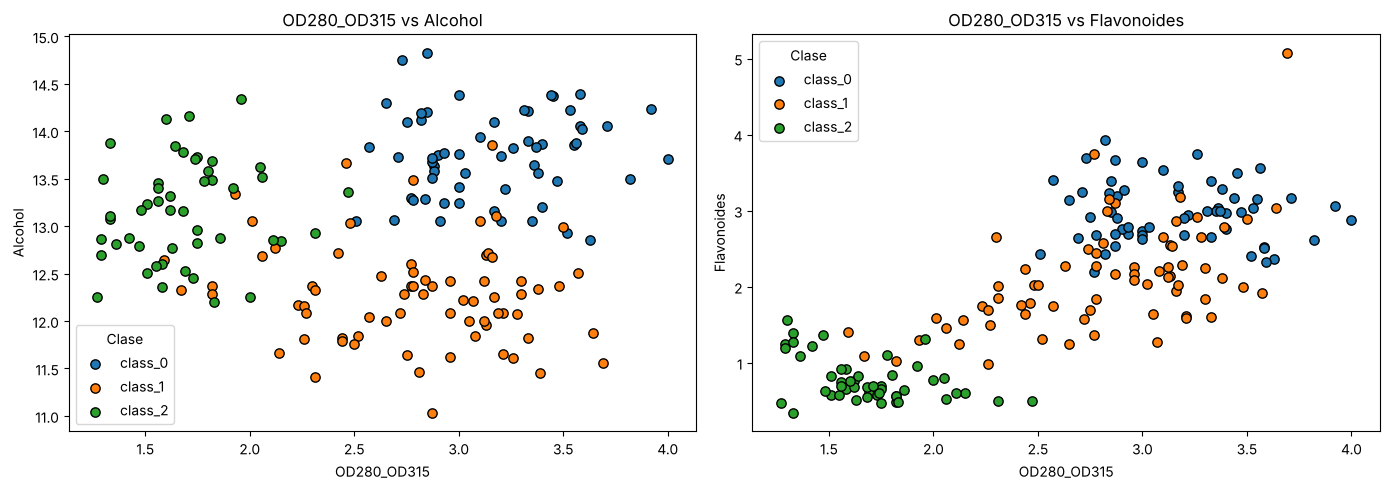

In [5]:
parejas = [('OD280_OD315', 'Alcohol'), ('OD280_OD315', 'Flavonoides')]
nombres_clase = datos_vino.target_names

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (a, b) in zip(axes, parejas):
    for k, nombre in enumerate(nombres_clase):
        m = (y == k)
        ax.scatter(X.loc[m, a], X.loc[m, b], label=nombre, edgecolor='k', s=45)
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f'{a} vs {b}')
    ax.legend(title='Clase')
plt.tight_layout()
plt.show()

---
## Paso 3: Evaluación de los tres clasificadores en cada pareja

Se usa el mismo esquema de la clase: `train_test_split` 70/30 con `stratify`, escalado para k-NN y Naive Bayes y árbol con `max_depth=4`. Para cada pareja se muestran las fronteras de decisión y la exactitud sobre el conjunto de prueba.

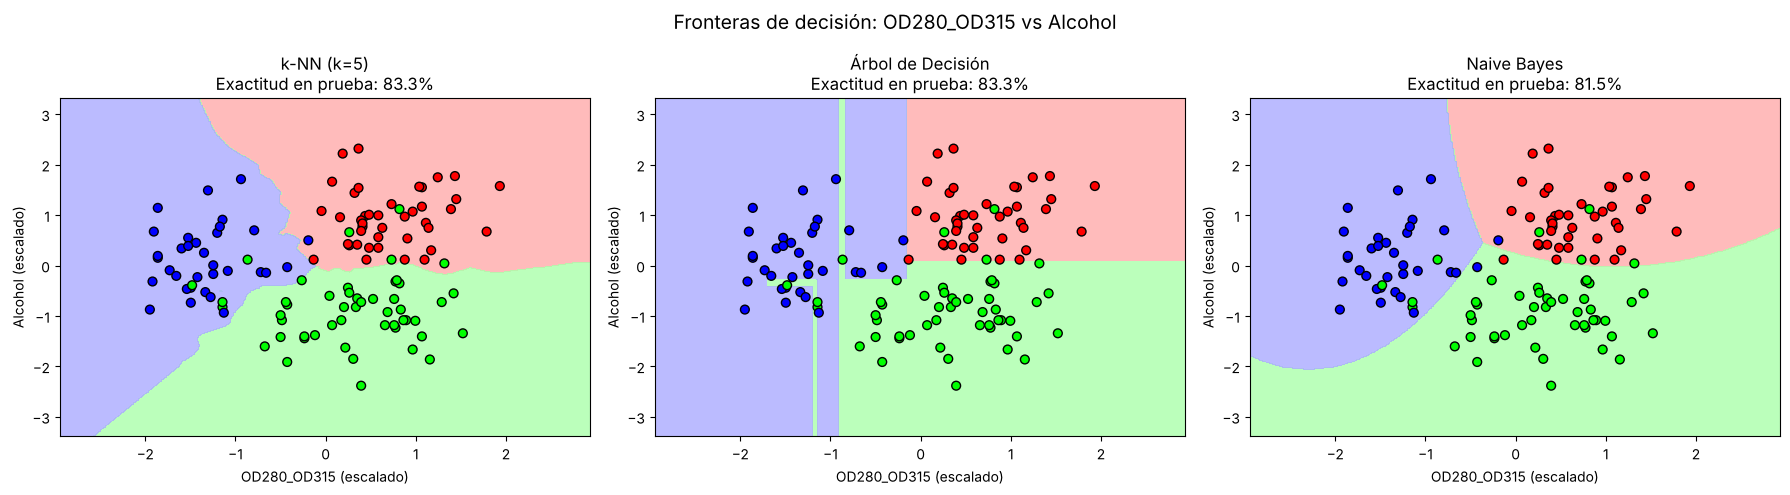

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

def evaluar_pareja(c1, c2):
    cols = [c1, c2]
    sc = StandardScaler()
    Xtr = sc.fit_transform(X_train[cols])
    Xte = sc.transform(X_test[cols])

    modelos = {
        'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5),
        'Árbol de Decisión': DecisionTreeClassifier(max_depth=4, random_state=42),
        'Naive Bayes': GaussianNB(),
    }
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    resultados = {}
    for ax, (nombre, modelo) in zip(axes, modelos.items()):
        modelo.fit(Xtr, y_train)
        acc = accuracy_score(y_test, modelo.predict(Xte))
        resultados[nombre] = acc
        x_min, x_max = Xtr[:, 0].min() - 1, Xtr[:, 0].max() + 1
        y_min, y_max = Xtr[:, 1].min() - 1, Xtr[:, 1].max() + 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
        zz = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=['#FFAAAA', '#AAFFAA', '#AAAAFF'], alpha=0.8)
        ax.scatter(Xtr[:, 0], Xtr[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_title(f'{nombre}\nExactitud en prueba: {acc*100:.1f}%')
        ax.set_xlabel(f'{c1} (escalado)'); ax.set_ylabel(f'{c2} (escalado)')
    fig.suptitle(f'Fronteras de decisión: {c1} vs {c2}', fontsize=14)
    plt.tight_layout()
    plt.show()
    return resultados

res_alcohol = evaluar_pareja('OD280_OD315', 'Alcohol')

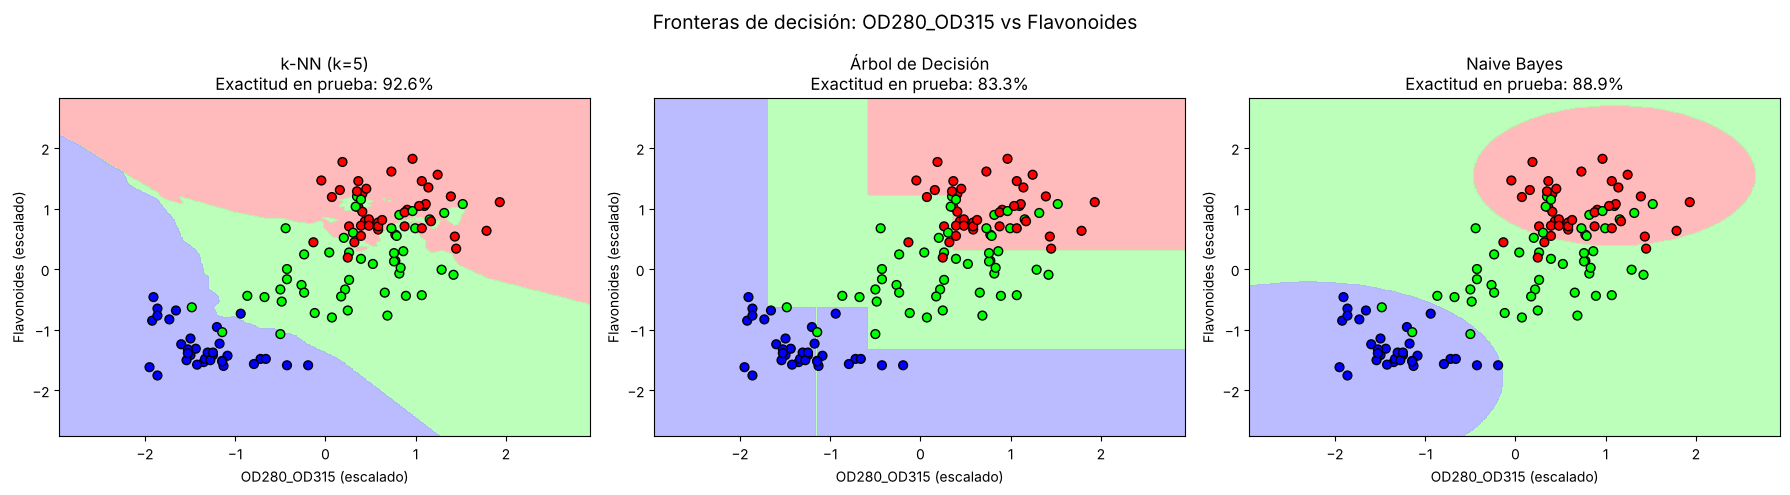

In [7]:
res_flavo = evaluar_pareja('OD280_OD315', 'Flavonoides')

,OD280_OD315 vs Alcohol,OD280_OD315 vs Flavonoides
k-NN (k=5),83.3%,92.6%
Árbol de Decisión,83.3%,83.3%
Naive Bayes,81.5%,88.9%


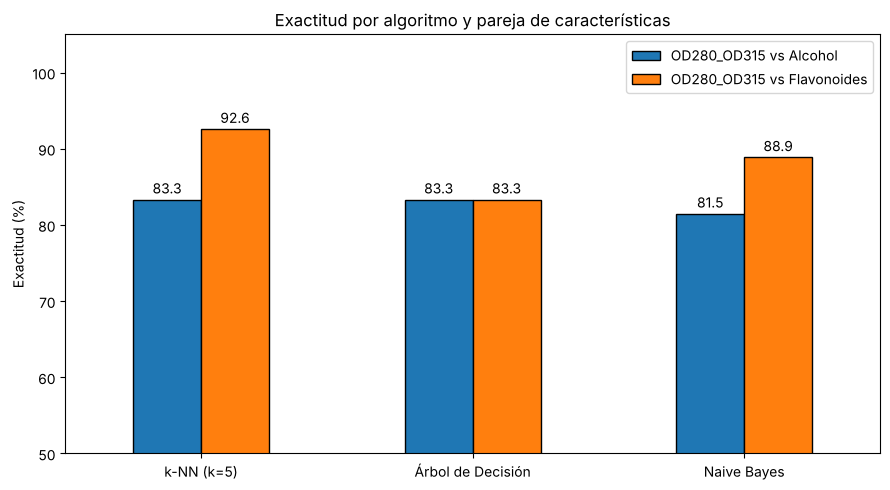

In [8]:
resumen = pd.DataFrame({
    'OD280_OD315 vs Alcohol': res_alcohol,
    'OD280_OD315 vs Flavonoides': res_flavo,
})
display((resumen * 100).round(1).style.format('{:.1f}%'))

ax = (resumen * 100).plot(kind='bar', figsize=(9, 5), rot=0, edgecolor='k')
ax.set_ylabel('Exactitud (%)'); ax.set_ylim(50, 105)
ax.set_title('Exactitud por algoritmo y pareja de características')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', padding=2)
plt.tight_layout()
plt.show()

---
## Paso 4: Conclusión

**3.ª columna elegida:** `OD280_OD315`, la más correlacionada con la clase (|r| ≈ 0.79) después de Flavonoides, y poco correlacionada con el Alcohol (≈ 0.07).

**Exactitud en el conjunto de prueba (54 vinos):**

| Algoritmo | OD280 vs Alcohol | OD280 vs Flavonoides |
|---|---|---|
| k-NN (k=5) | 83.3% | **92.6%** |
| Árbol de Decisión | 83.3% | 83.3% |
| Naive Bayes | 81.5% | 88.9% |

**Pareja de columnas:** `OD280_OD315` + `Flavonoides` separa mucho mejor las clases que `OD280_OD315` + `Alcohol`. Con el Alcohol, la clase 0 (rojo) y la clase 1 (verde) quedan mezcladas en la zona central y todos los modelos se quedan en torno al 82-83%. Con Flavonoides las tres clases forman grupos más definidos (azul abajo a la izquierda, rojo arriba a la derecha y verde en medio).

**Representación gráfica más clara: Naive Bayes** (con la pareja OD280 vs Flavonoides). Dibuja una región compacta y suave para cada clase (óvalos), sin zonas aisladas ni cortes bruscos, y se entiende de un vistazo dónde está cada clase. Además su exactitud (88.9%) es alta.

- **k-NN** logra la mayor exactitud (92.6%), pero su frontera es irregular y tiene "islas" en la zona donde se mezclan rojo y verde, por lo que su gráfico es más difícil de leer. Es la mejor opción si el criterio es solo la exactitud.
- **Árbol de Decisión** produce cortes rectos fáciles de traducir a reglas, pero las regiones en escalera y fragmentadas (incluida una franja delgada) se ajustan poco a la forma curva de los grupos, y es el de menor exactitud (83.3%).

*Nota:* con solo 54 vinos de prueba, una diferencia de un par de vinos mueve varios puntos porcentuales, así que las diferencias pequeñas deben tomarse con cautela.